# Forecasting Food In and Food Out at Three Warehouse Locations
**Foundations of Statistical Analysis and Machine Learning · 2026/27**

**Question:** How much food might arrive and leave **Dublin, Cork and Galway** each day for the 30 days after the last CSV date? I predict **daily recorded weight (kg)** for each location and flow. This gives six simple daily series. It can help with space and distribution planning, but it cannot predict spoilage or stock levels.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')
TEAL, ORANGE, NAVY = '#168a83', '#e69b4b', '#20344a'
data = pd.read_csv('data/bc_transaction_data_2021-05-04_to_2026-10-29.csv', low_memory=False)

## 1. Understand the CSV

The warehouse field is `location_code`, with Dublin, Cork and Galway. `branch_id` has many values and refers to a different level, so it is not our warehouse target. First check the columns, missing values, transaction types and some real rows.

In [2]:
print('Rows and columns:', data.shape)
print('Columns and types:')
display(data.dtypes.to_frame('type'))
missing = pd.DataFrame({'count': data.isna().sum(),
                        'percent': (data.isna().mean() * 100).round(2)})
display(missing)
print('Location codes:', data['location_code'].value_counts().to_dict())
print('Transaction types:', data['transaction_type'].value_counts().to_dict())
print('Identical-looking rows:', data.duplicated().sum())
display(data.head(3))

Rows and columns: (962060, 11)
Columns and types:


,type
transaction_date,object
branch_id,float64
item_id,int64
category_id,float64
gross_weight,float64
transaction_weight,float64
item_quantity,float64
transaction_type,object
displayName,object
weightunit,object


,count,percent
transaction_date,0,0.00
branch_id,4858,0.50
item_id,0,0.00
category_id,1191,0.12
gross_weight,0,0.00
transaction_weight,7,0.00
item_quantity,0,0.00
transaction_type,0,0.00
displayName,0,0.00
weightunit,0,0.00


Location codes: {'DUBLIN': 646195, 'CORK': 181367, 'GALWAY': 134498}
Transaction types: {'Food Out': 785352, 'Food In': 129020, 'Movement': 17454, 'Waste Transfer': 17174, 'Interhub': 9570, 'Not Posted': 2702, 'Return': 788}


Identical-looking rows: 200036


,transaction_date,branch_id,item_id,category_id,gross_weight,transaction_weight,item_quantity,transaction_type,displayName,weightunit,location_code
0,2025-12-24,314.0,9098,372.0,80.0,22.08,23.0,Food Out,Chilled-Brady-Crumbed Ham Slices-80 G,g,DUBLIN
1,2025-12-24,314.0,21049,364.0,100.0,3.60,3.0,Food Out,Chilled-Green Farm-Chargrilled Chicken Breast ...,g,DUBLIN
2,2025-12-24,8586.0,14856,29.0,820.0,8.20,10.0,Food Out,Ambient-Brennans-white-batch-loaf-820g,g,DUBLIN


## 2. Clean the records

I use only `Food In` and `Food Out` for forecasting. `Waste Transfer` is shown separately in EDA. `weightunit` describes the package unit; the recorded `transaction_weight` appears to be kilograms for `g` and `Kg` products, but the CSV has no data dictionary to confirm this. I leave out `Default` units and missing or non-positive weights. I keep duplicate-looking rows because there is no transaction ID to prove they are errors.

In [3]:
# Check dates and weights before filtering anything
data['date'] = pd.to_datetime(data['transaction_date'], errors='coerce')
print('Actual date range:', data['date'].min(), 'to', data['date'].max())
print('Invalid dates:', data['date'].isna().sum())
movement = data[data['transaction_type'].isin(['Food In', 'Food Out'])]
print('Missing weights:', movement['transaction_weight'].isna().sum())
print('Zero weights:', (movement['transaction_weight'] == 0).sum())
print('Negative weights:', (movement['transaction_weight'] < 0).sum())
print('Package units by flow:')
display(pd.crosstab(movement['transaction_type'], movement['weightunit']))

Actual date range: 2021-05-04 00:00:00 to 2026-10-29 00:00:00
Invalid dates: 0
Missing weights: 7
Zero weights: 292
Negative weights: 0
Package units by flow:


weightunit,Default,Kg,g
transaction_type,,,
Food In,8677,46158,74185
Food Out,17654,286223,481475


In [4]:
# Keep records with a usable date, location and positive recorded weight
usable = data.dropna(subset=['date', 'location_code', 'transaction_weight']).copy()
usable = usable[(usable['transaction_weight'] > 0) &
                usable['weightunit'].isin(['g', 'Kg'])]
food = usable[usable['transaction_type'].isin(['Food In', 'Food Out'])].copy()
print('Usable Food In / Food Out rows:', len(food))
display(food.groupby(['location_code', 'transaction_type'])['transaction_weight']
        .agg(['count', 'median', 'max']).round(1))

Usable Food In / Food Out rows: 887763


count  median       max
location_code transaction_type                          
CORK          Food In            17778    36.0   71395.2
              Food Out          155386     8.3   20014.6
DUBLIN        Food In            93067     7.0  120198.0
              Food Out          499295     7.2    7500.0
GALWAY        Food In             9448    50.7    6300.0
              Food Out          112789    10.0    3168.0

## 3. Make six daily time series

All six location-and-flow series have recorded activity by **29 March 2022**, so I start the common daily calendar there. A missing location-and-flow day becomes **zero recorded kg**. This is a practical assumption: a closure or missing log could also explain a blank day. The final 30 calendar days in the CSV are held out for testing.

In [5]:
# Make one row per date, location and flow
start_date = pd.Timestamp('2022-03-29')
last_date = data['date'].max()
test_start = last_date - pd.Timedelta(days=29)
validation_start = test_start - pd.Timedelta(days=60)
locations = ['DUBLIN', 'CORK', 'GALWAY']
flows = ['Food In', 'Food Out']
groups = pd.DataFrame([(place, flow) for place in locations for flow in flows],
                      columns=['location_code', 'transaction_type'])
calendar = pd.DataFrame({'date': pd.date_range(start_date, last_date)})
daily = calendar.merge(groups, how='cross')
totals = food.groupby(['date', 'location_code', 'transaction_type'], as_index=False)['transaction_weight'].sum()
daily = daily.merge(totals, on=['date', 'location_code', 'transaction_type'], how='left')
daily['kg'] = daily['transaction_weight'].fillna(0)
daily = daily.drop(columns='transaction_weight')
print('Final test:', test_start.date(), 'to', last_date.date(), '| rows:', len(daily[daily.date >= test_start]))

Final test: 2026-09-30 to 2026-10-29 | rows: 180


## 4. Explore warehouse food movement

The EDA uses only dates **before the final test period**. This lets us study patterns without looking at the future holdout while building the models.

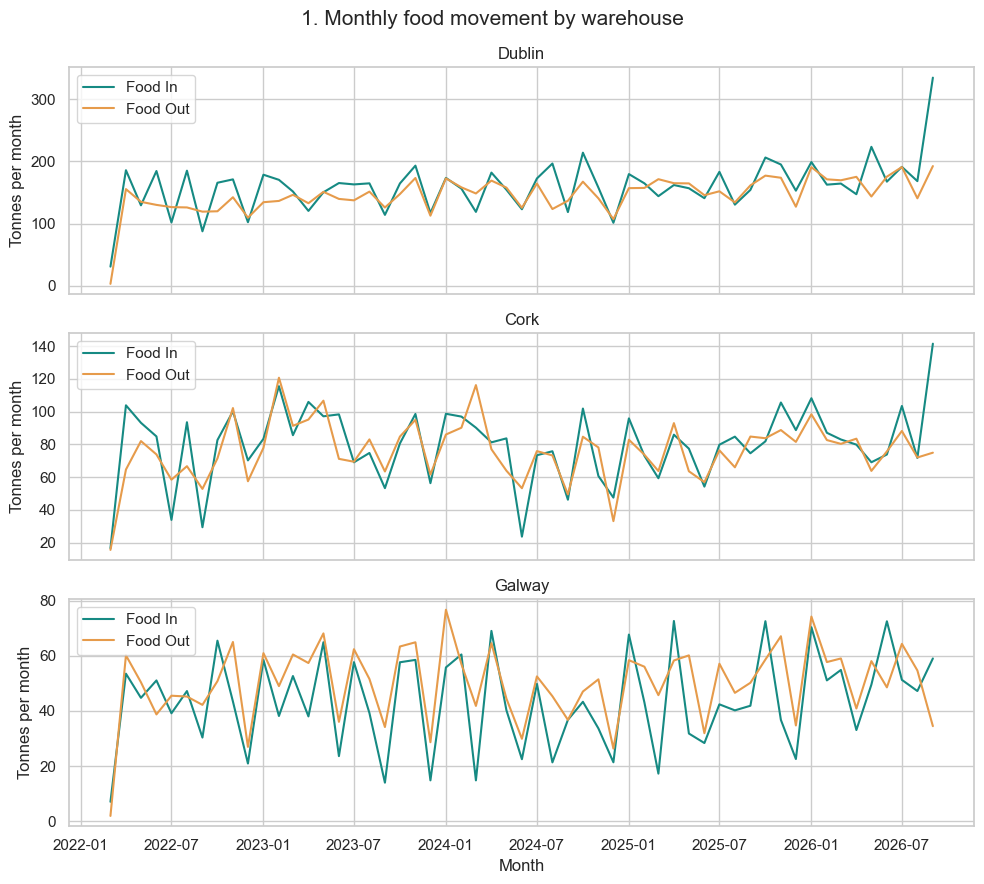

In [6]:
# Graph 1: monthly Food In and Food Out for each location
old_food = food[(food['date'] >= start_date) & (food['date'] < test_start)]
monthly = old_food.groupby([pd.Grouper(key='date', freq='MS'),
                            'location_code', 'transaction_type'])['transaction_weight'].sum().reset_index()
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, place in zip(axes, locations):
    part = monthly[monthly['location_code'] == place]
    for flow, colour in [('Food In', TEAL), ('Food Out', ORANGE)]:
        line = part[part['transaction_type'] == flow]
        ax.plot(line['date'], line['transaction_weight'] / 1000, label=flow, color=colour)
    ax.set(title=place.title(), ylabel='Tonnes per month')
    ax.legend()
axes[-1].set_xlabel('Month')
fig.suptitle('1. Monthly food movement by warehouse', fontsize=15)
plt.tight_layout()
plt.savefig('figures/01_monthly_by_warehouse.png')
plt.show()

**Graph 1:** Dublin has the largest monthly movement. A sharp Food In rise in September 2026 includes unusually large recorded deliveries. The lines are separate transaction flows, not a stock balance.

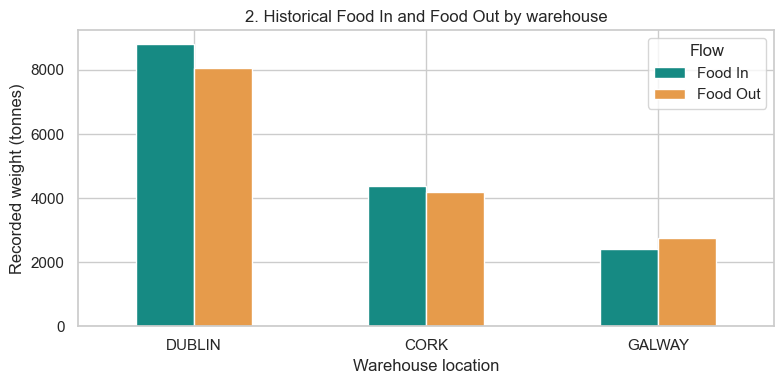

transaction_type,Food In,Food Out
location_code,,
DUBLIN,8794988.3,8063286.7
CORK,4385028.2,4180213.5
GALWAY,2396240.9,2755183.2


In [7]:
# Graph 2: total recorded incoming and outgoing weight by location
warehouse_totals = old_food.groupby(['location_code', 'transaction_type'])['transaction_weight'].sum().unstack()
warehouse_totals = warehouse_totals.reindex(locations)[flows]
ax = (warehouse_totals / 1000).plot(kind='bar', figsize=(8, 4), color=[TEAL, ORANGE], rot=0)
ax.set(title='2. Historical Food In and Food Out by warehouse',
       xlabel='Warehouse location', ylabel='Recorded weight (tonnes)')
plt.legend(title='Flow')
plt.tight_layout()
plt.savefig('figures/02_warehouse_totals.png')
plt.show()
display(warehouse_totals.round(1))

**Graph 2:** Compare the scale of receiving and distribution at each location. Food In minus Food Out is **not** an inventory figure because the CSV has no stock snapshots or linked batches.

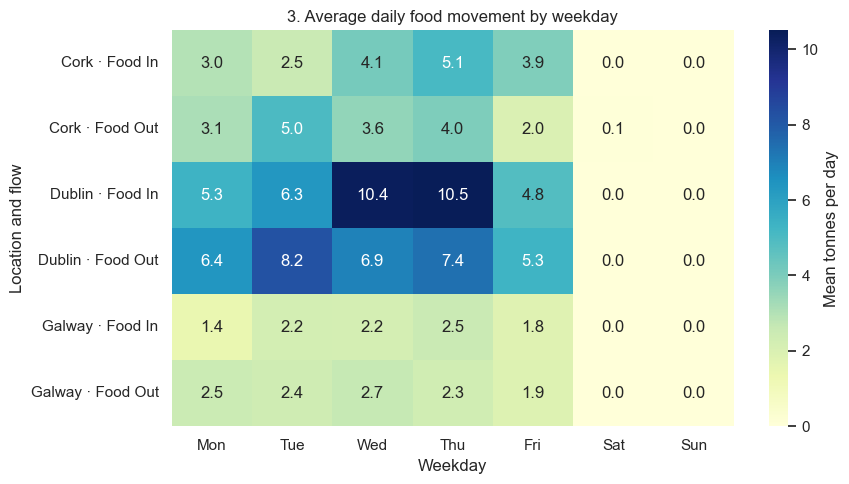

In [8]:
# Graph 3: average daily weight by weekday, including zero-record dates
earlier = daily[daily['date'] < test_start].copy()
earlier['weekday'] = earlier['date'].dt.dayofweek
weekday = earlier.groupby(['location_code', 'transaction_type', 'weekday'])['kg'].mean().unstack()
weekday = weekday.reindex(columns=range(7)) / 1000
weekday.columns = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekday.index = [f'{place.title()} · {flow}' for place, flow in weekday.index]
plt.figure(figsize=(9, 5))
sns.heatmap(weekday, annot=True, fmt='.1f', cmap='YlGnBu',
            cbar_kws={'label': 'Mean tonnes per day'})
plt.title('3. Average daily food movement by weekday')
plt.xlabel('Weekday')
plt.ylabel('Location and flow')
plt.tight_layout()
plt.savefig('figures/03_weekday_heatmap.png')
plt.show()

**Graph 3:** Dublin Food In is busiest on Wednesdays and Thursdays, averaging about 10.4 and 10.5 tonnes per day. Recorded weekend movement is almost zero. The heatmap includes zero-record dates.

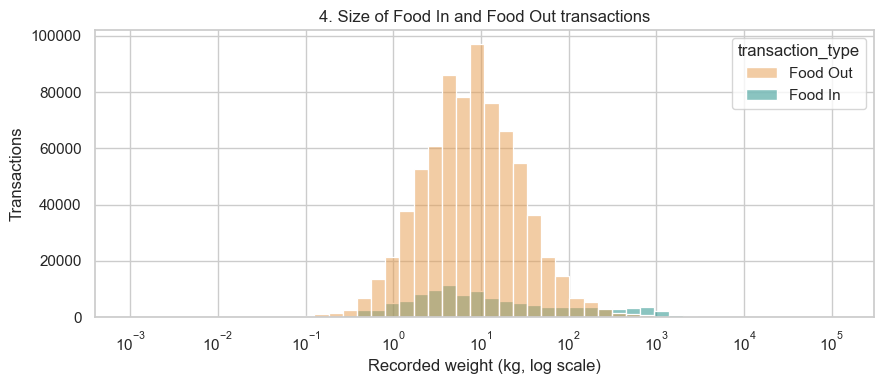

In [9]:
# Graph 4: compare small and large transaction sizes
plt.figure(figsize=(9, 4))
sns.histplot(data=old_food, x='transaction_weight', hue='transaction_type',
             bins=50, log_scale=True, palette={'Food In': TEAL, 'Food Out': ORANGE})
plt.title('4. Size of Food In and Food Out transactions')
plt.xlabel('Recorded weight (kg, log scale)')
plt.ylabel('Transactions')
plt.tight_layout()
plt.savefig('figures/04_transaction_sizes.png')
plt.show()

**Graph 4:** Most records are small and a few are very large. The log scale makes both ends readable; large donations and distributions should be checked, but not automatically deleted.

### Check unusual quantities

IQR means the middle 50% of values. I flag weights above **Q3 + 1.5 × IQR** using pre-test records, separately for Food In and Food Out. The flags are for investigation; all rows remain in the analysis.

In [10]:
# Flag large transactions using only older, pre-test data
for flow in flows:
    part = old_food[old_food['transaction_type'] == flow]
    q1, q3 = part['transaction_weight'].quantile([.25, .75])
    limit = q3 + 1.5 * (q3 - q1)
    flagged = part[part['transaction_weight'] > limit]
    print(flow, 'IQR upper limit:', round(limit, 1), 'kg | flagged:', len(flagged))
    display(flagged.nlargest(3, 'transaction_weight')[
        ['date', 'location_code', 'transaction_weight', 'displayName']])

Food In IQR upper limit: 143.8 kg | flagged: 20613


,date,location_code,transaction_weight,displayName
928435,2026-09-10,DUBLIN,120198.0,Frozen-Golden Bakes-White Chocolate Chunk Coo...
928406,2026-09-10,CORK,71395.2,Frozen-Golden Bakes-White Chocolate Chunk Coo...
521700,2024-08-29,DUBLIN,56000.0,Ambient-Heinz-Malt Vinegar Sachets(200x7g)-1.4kg


Food Out IQR upper limit: 40.2 kg | flagged: 69736


,date,location_code,transaction_weight,displayName
80508,2024-03-04,CORK,20014.56,Ambient - Freshona - Jackfruit in Salted water...
459728,2023-04-14,CORK,19918.08,Ambient-Lucozade Energy-Orange- 6 X 380ml
521252,2023-02-20,CORK,19008.00,AMBIENT-LUCOZADE-ZERO SUGAR PINK LEMONADE-500ML


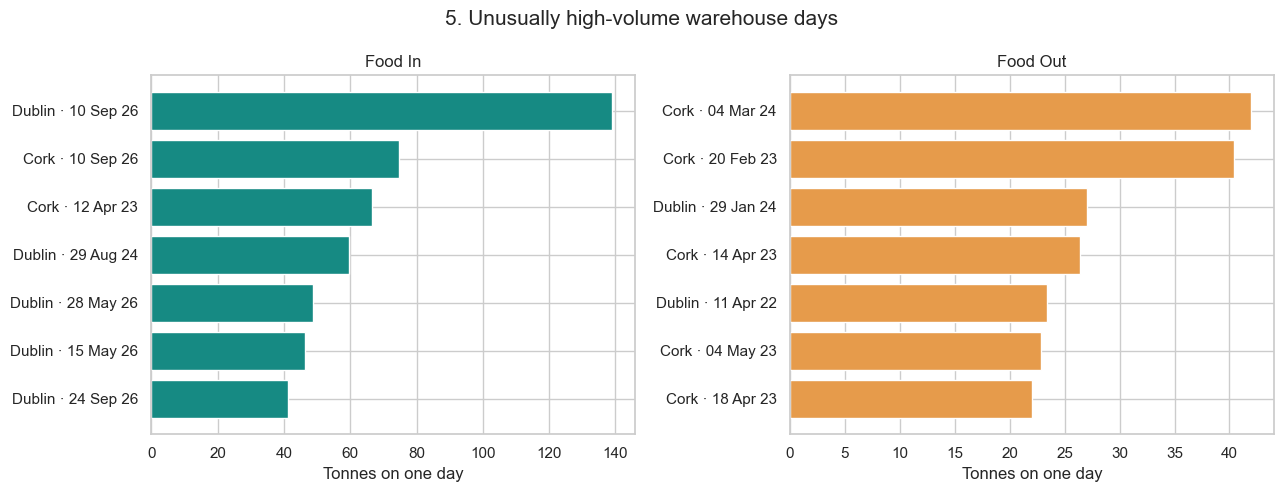

In [11]:
# Graph 5: the largest daily totals, with each warehouse shown separately
big_days = old_food.groupby(['date', 'location_code', 'transaction_type'])['transaction_weight'].sum().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, flow, colour in zip(axes, flows, [TEAL, ORANGE]):
    top = big_days[big_days['transaction_type'] == flow].nlargest(7, 'transaction_weight')
    labels = top['location_code'].str.title() + ' · ' + top['date'].dt.strftime('%d %b %y')
    ax.barh(labels[::-1], top['transaction_weight'][::-1] / 1000, color=colour)
    ax.set(title=flow, xlabel='Tonnes on one day')
fig.suptitle('5. Unusually high-volume warehouse days', fontsize=15)
plt.tight_layout()
plt.savefig('figures/05_big_days.png')
plt.show()

**Graph 5:** The largest Food In day is a very large September 2026 delivery. It could be genuine or a recording error. Retaining it reflects the recorded history, while the model may struggle to predict rare spikes.

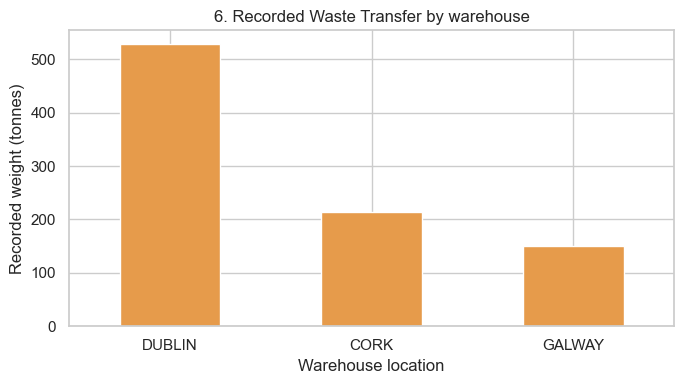

,recorded_waste_transfer_kg
location_code,
DUBLIN,527510.7
CORK,213714.8
GALWAY,150359.5


In [12]:
# Graph 6: Waste Transfer is a separate recorded transaction type
waste = usable[(usable['transaction_type'] == 'Waste Transfer') &
               (usable['date'] >= start_date) & (usable['date'] < test_start)]
waste_total = waste.groupby('location_code')['transaction_weight'].sum().reindex(locations)
ax = (waste_total / 1000).plot(kind='bar', figsize=(7, 4), color=ORANGE, rot=0)
ax.set(title='6. Recorded Waste Transfer by warehouse',
       xlabel='Warehouse location', ylabel='Recorded weight (tonnes)')
plt.tight_layout()
plt.savefig('figures/06_waste_transfer.png')
plt.show()
display(waste_total.round(1).to_frame('recorded_waste_transfer_kg'))

**Graph 6:** Dublin has the largest recorded Waste Transfer total (about 528 tonnes), followed by Cork (214 tonnes) and Galway (150 tonnes). The CSV does not explain each transfer or give stock and expiry data, so this is **not** a measured spoilage rate.

## 5. Make simple forecasting features

The inputs are **location, flow, weekday, month, yesterday’s weight (lag 1)** and **the weight from 7 days ago (lag 7)**. Lags use past values from the *same* location and flow. We drop only the first seven calendar days of each series because their lag 7 value is unavailable. For a 30-day forecast, the model must use its own earlier predictions when the real future weights are unknown.

In [13]:
# Add two past-weight features for each warehouse and flow
daily = daily.sort_values(['location_code', 'transaction_type', 'date']).reset_index(drop=True)
daily['weekday'] = daily['date'].dt.dayofweek
daily['month'] = daily['date'].dt.month
for lag in [1, 7]:
    daily[f'lag_{lag}'] = daily.groupby(['location_code', 'transaction_type'])['kg'].shift(lag)

# Keep category inputs as yes/no columns and lag weights as numbers
def features(rows):
    X = pd.get_dummies(rows[['location_code', 'transaction_type',
                             'weekday', 'month']].astype(str), dtype=int)
    X['lag_1'] = rows['lag_1'].to_numpy()
    X['lag_7'] = rows['lag_7'].to_numpy()
    return X

train = daily[(daily['date'] < test_start) & daily['lag_7'].notna()].copy()
X_train = features(train)
print('Training rows:', len(train), '| Test rows:', len(daily[daily.date >= test_start]))

Training rows: 9834 | Test rows: 180


In [14]:
# Forecast one day at a time so later lags use predictions, not future actuals
def forecast_period(model, past, dates, columns):
    history = {(row.date, row.location_code, row.transaction_type): row.kg
               for row in past.itertuples()}
    results = []
    for date in dates:
        today = groups.copy()
        today['date'] = date
        today['weekday'] = date.dayofweek
        today['month'] = date.month
        for lag in [1, 7]:
            today[f'lag_{lag}'] = [history[(date - pd.Timedelta(days=lag), place, flow)]
                                   for place, flow in zip(today['location_code'], today['transaction_type'])]
        X_today = features(today).reindex(columns=columns, fill_value=0)
        today['predicted_kg'] = np.maximum(model.predict(X_today), 0)
        for row in today.itertuples():
            history[(date, row.location_code, row.transaction_type)] = row.predicted_kg
        results.append(today)
    return pd.concat(results, ignore_index=True)

### Choose one small Random Forest setting

The earlier 60-day validation is forecast **one day at a time**, just like the final test and future forecast. This checks the model without giving it actual values from later validation days. Linear Regression remains the simple baseline.

In [15]:
# Choose between two simple forest settings on earlier dates
validation_train = daily[(daily['date'] < validation_start) & daily['lag_7'].notna()]
validation = daily[(daily['date'] >= validation_start) & (daily['date'] < test_start)]
X_val_train = features(validation_train)
validation_dates = pd.date_range(validation_start, test_start - pd.Timedelta(days=1))
for trees, depth, leaf in [(50, 8, 5), (100, 10, 3)]:
    trial = RandomForestRegressor(n_estimators=trees, max_depth=depth,
                                  min_samples_leaf=leaf, random_state=42)
    trial.fit(X_val_train, validation_train['kg'])
    predicted = forecast_period(trial, daily[daily['date'] < validation_start],
                                validation_dates, X_val_train.columns)
    checked = validation.merge(predicted[['date', 'location_code', 'transaction_type',
                                          'predicted_kg']], on=['date', 'location_code', 'transaction_type'])
    print(trees, 'trees, depth', depth, '— recursive validation MAE:',
          round(mean_absolute_error(checked['kg'], checked['predicted_kg']), 1), 'kg')

50 trees, depth 8 — recursive validation MAE: 2493.1 kg


100 trees, depth 10 — recursive validation MAE: 2494.6 kg


The **50-tree** setting has slightly lower recursive validation MAE, so I use it for the final test. Both final models predict the same six series and same 30 unseen dates.

In [16]:
# Train both models on older dates, then forecast the test recursively
test_dates = pd.date_range(test_start, last_date)
past_test = daily[daily['date'] < test_start]
linear = LinearRegression()
linear.fit(X_train, train['kg'])
linear_test = forecast_period(linear, past_test, test_dates, X_train.columns)
forest = RandomForestRegressor(n_estimators=50, max_depth=8,
                               min_samples_leaf=5, random_state=42)
forest.fit(X_train, train['kg'])
forest_test = forecast_period(forest, past_test, test_dates, X_train.columns)
keys = ['date', 'location_code', 'transaction_type']
test = daily[daily['date'] >= test_start][keys + ['kg']].copy()
test = test.merge(linear_test[keys + ['predicted_kg']].rename(columns={'predicted_kg': 'Linear Regression'}), on=keys)
test = test.merge(forest_test[keys + ['predicted_kg']].rename(columns={'predicted_kg': 'Random Forest'}), on=keys)
linear_pred, forest_pred = test['Linear Regression'], test['Random Forest']

## 6. Compare predictions on the unseen final 30 days

Both models forecast the whole 30-day test **recursively**: once the test starts, they use their own predicted weights for any later lag. They never use the actual Food In or Food Out weights from the test to make predictions. MAE is average absolute error in kg per location-flow-day; RMSE gives extra weight to large misses. Negative predictions are clipped to zero.

In [17]:
# Score both models on the same 180 unseen targets
actual = test['kg']
comparison = pd.DataFrame({
    'model': ['Linear Regression', 'Random Forest'],
    'MAE_kg': [mean_absolute_error(actual, linear_pred), mean_absolute_error(actual, forest_pred)],
    'RMSE_kg': [np.sqrt(mean_squared_error(actual, linear_pred)),
                np.sqrt(mean_squared_error(actual, forest_pred))],
    'R2': [r2_score(actual, linear_pred), r2_score(actual, forest_pred)]
})
display(comparison.round(2))
comparison.to_csv('outputs/model_comparison.csv', index=False)

,model,MAE_kg,RMSE_kg,R2
0,Linear Regression,2744.60,5042.71,0.32
1,Random Forest,2327.01,4824.82,0.37


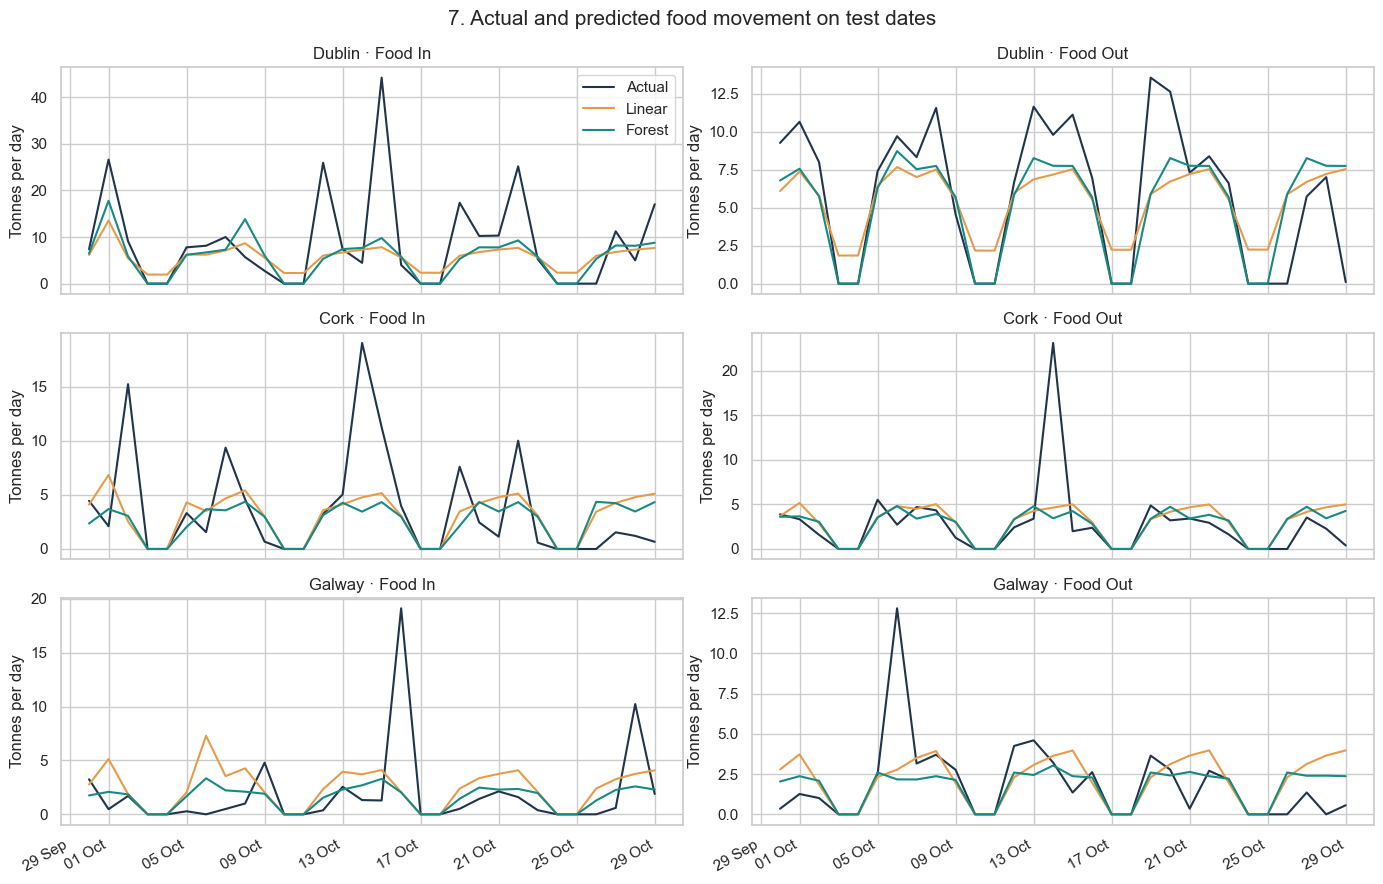

In [18]:
# Graph 7: actual versus both models for each location and flow
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
for row, place in enumerate(locations):
    for col, flow in enumerate(flows):
        ax = axes[row, col]
        part = test[(test['location_code'] == place) & (test['transaction_type'] == flow)]
        ax.plot(part['date'], part['kg'] / 1000, label='Actual', color=NAVY)
        ax.plot(part['date'], part['Linear Regression'] / 1000, label='Linear', color=ORANGE)
        ax.plot(part['date'], part['Random Forest'] / 1000, label='Forest', color=TEAL)
        ax.set(title=f'{place.title()} · {flow}', ylabel='Tonnes per day')
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
axes[0, 0].legend()
fig.suptitle('7. Actual and predicted food movement on test dates', fontsize=15)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('figures/07_test_predictions.png')
plt.show()

**Graph 7:** The lagged Random Forest has lower test MAE (2,327 kg versus 2,745 kg per location-flow-day). Both models follow regular days but miss some large spikes, especially Dublin Food In. Adding the two lags changed the forest MAE only slightly from the earlier no-lag result.

In [19]:
# Compare the total actual and predicted weight over the whole test month
test_totals = test.groupby(['location_code', 'transaction_type'])[['kg', 'Random Forest']].sum()
test_totals.columns = ['actual_kg', 'predicted_kg']
test_totals['difference_percent'] = 100 * (test_totals['predicted_kg'] / test_totals['actual_kg'] - 1)
display(test_totals.round(1))
print('All six series — actual:', round(test_totals['actual_kg'].sum()),
      'kg | predicted:', round(test_totals['predicted_kg'].sum()), 'kg')

actual_kg  predicted_kg  difference_percent
location_code transaction_type                                             
CORK          Food In            108993.4       77501.7               -28.9
              Food Out            82954.6       82047.1                -1.1
DUBLIN        Food In            265233.9      172552.2               -34.9
              Food Out           176946.7      156391.3               -11.6
GALWAY        Food In             55445.4       47817.3               -13.8
              Food Out            57111.5       52653.3                -7.8

All six series — actual: 746685 kg | predicted: 588963 kg


**Was it close?** The lagged forest predicted **588,963 kg** across the six test series; the CSV recorded **746,685 kg**. That is about **21% too low**. Dublin Food In was about **35% too low**, and Cork Food In about **29% too low**. Use spare capacity when planning for large arrivals.

In [20]:
# See which location and flow the forest finds hardest
test['forest_absolute_error'] = (test['kg'] - test['Random Forest']).abs()
error_by_group = test.groupby(['location_code', 'transaction_type'])['forest_absolute_error'].mean()
error_by_group = error_by_group.sort_values(ascending=False)
display(error_by_group.round(1).to_frame('Random_Forest_MAE_kg'))
error_by_group.to_csv('outputs/error_by_warehouse_flow.csv', header=['Random_Forest_MAE_kg'])

,,Random_Forest_MAE_kg
location_code,transaction_type,
DUBLIN,Food In,4782.7
CORK,Food In,2755.0
DUBLIN,Food Out,1912.3
GALWAY,Food In,1703.7
CORK,Food Out,1647.0
GALWAY,Food Out,1161.3


## 7. Forecast the next 30 days after the CSV

I refit the lower-MAE model on all recorded dates. For each new day, its predicted Food In and Food Out weights become the lag values available to the next forecast day. The output has six predictions per day and is marked as **forecast, not observed**.

In [21]:
# Refit the chosen model on all dates with lag features available
best = comparison.loc[comparison['MAE_kg'].idxmin(), 'model']
if best == 'Random Forest':
    final_model = RandomForestRegressor(n_estimators=50, max_depth=8,
                                        min_samples_leaf=5, random_state=42)
else:
    final_model = LinearRegression()
all_rows = daily.dropna(subset=['lag_1', 'lag_7'])
final_model.fit(features(all_rows), all_rows['kg'])
print('Chosen model:', best)

Chosen model: Random Forest


In [22]:
# Forecast 30 dates after the last recorded date, one at a time
future_dates = pd.date_range(last_date + pd.Timedelta(days=1), periods=30)
future = forecast_period(final_model, daily, future_dates, X_train.columns)
future['status'] = 'forecast_not_observed'
future[['date', 'location_code', 'transaction_type', 'predicted_kg', 'status']].to_csv(
    'outputs/next_30_days_forecast.csv', index=False, date_format='%Y-%m-%d')
forecast_total = future.groupby(['location_code', 'transaction_type'])['predicted_kg'].sum()
display(forecast_total.round(1).to_frame('predicted_30_day_kg'))
forecast_total.to_csv('outputs/warehouse_forecast_summary.csv', header=['predicted_30_day_kg'])

predicted_30_day_kg
location_code transaction_type                     
CORK          Food In                       76082.7
              Food Out                      79509.6
DUBLIN        Food In                      164210.0
              Food Out                     147766.7
GALWAY        Food In                       45221.2
              Food Out                      54338.8

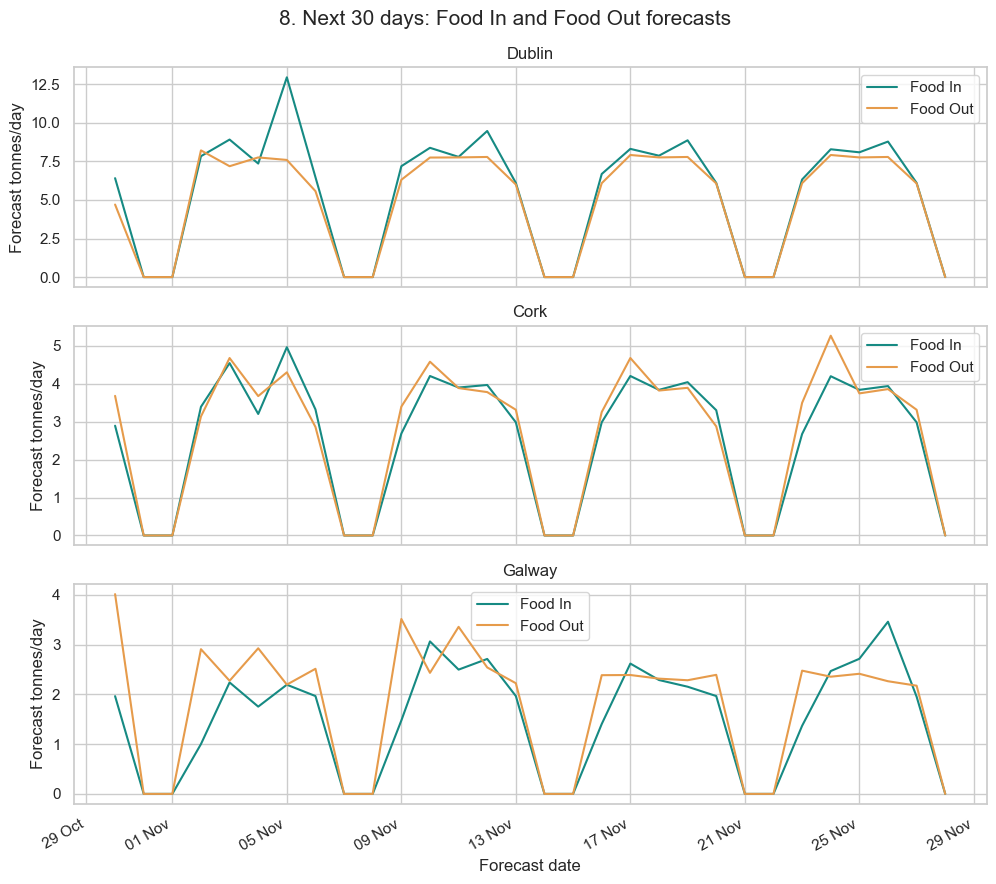

In [23]:
# Graph 8: future Food In and Food Out for each warehouse
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, place in zip(axes, locations):
    part = future[future['location_code'] == place]
    for flow, colour in [('Food In', TEAL), ('Food Out', ORANGE)]:
        line = part[part['transaction_type'] == flow]
        ax.plot(line['date'], line['predicted_kg'] / 1000, label=flow, color=colour)
    ax.set(title=place.title(), ylabel='Forecast tonnes/day')
    ax.legend()
axes[-1].set_xlabel('Forecast date')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
fig.suptitle('8. Next 30 days: Food In and Food Out forecasts', fontsize=15)
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig('figures/08_next_30_days.png')
plt.show()

**Graph 8:** These are recursive predictions for the 30 days after the CSV ends. Dublin has the largest totals: about **164 tonnes Food In** and **148 tonnes Food Out**. Forecast errors can build up because later lag inputs are earlier predictions.

## Conclusion and limits

This is a simple planning forecast for **three locations × two flows**, not a stock or spoilage forecast. The two lag features add recent history, but forecasts over many days can drift because later lags use earlier predictions. It cannot show inventory, exact waste, storage time or expiry risk. `Waste Transfer` is a separate recorded movement and cannot be turned into a reliable spoilage rate without more information. The CSV has no stated licence or formal unit dictionary. Transaction details may be commercially sensitive; if linked data identifies people, relevant [GDPR rules](https://eur-lex.europa.eu/eli/reg/2016/679/oj/eng/) apply.

See `report_notes.md` for measured results and research references.